<h1>Train — DenseNet-121</h1>

Trains and evaluates DenseNet-121 using the tuned hyperparameters from `ARCH_HYPERPARAMS["densenet121"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["densenet121"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"DenseNet-121: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

DenseNet-121: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with DenseNet-121)
# ---------------------------------------------------------
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
in_f = model.classifier.in_features
model.classifier = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[DenseNet-121] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[DenseNet-121] Epoch   1/100 | LR: 1.39e-04 | train loss 0.9117 acc 0.641 | val loss 0.7240 acc 0.703 *


[DenseNet-121] Epoch   2/100 | LR: 1.39e-04 | train loss 0.7163 acc 0.709 | val loss 0.6240 acc 0.751 *


[DenseNet-121] Epoch   3/100 | LR: 1.39e-04 | train loss 0.6856 acc 0.731 | val loss 0.5967 acc 0.751 *


[DenseNet-121] Epoch   4/100 | LR: 1.39e-04 | train loss 0.5826 acc 0.777 | val loss 0.6032 acc 0.712


...

[DenseNet-121] Epoch  16/100 | LR: 1.39e-04 | train loss 0.2623 acc 0.913 | val loss 0.5722 acc 0.808


[DenseNet-121] Epoch  17/100 | LR: 1.39e-04 | train loss 0.2164 acc 0.921 | val loss 0.6600 acc 0.777


[DenseNet-121] Epoch  18/100 | LR: 1.39e-04 | train loss 0.1978 acc 0.937 | val loss 0.5681 acc 0.803


[DenseNet-121] Epoch  19/100 | LR: 1.39e-04 | train loss 0.1834 acc 0.939 | val loss 0.6664 acc 0.799


[DenseNet-121] Epoch  20/100 | LR: 1.39e-04 | train loss 0.2122 acc 0.914 | val loss 0.6067 acc 0.795

[DenseNet-121] No val loss improvement for 10 epochs — stopping early at epoch 20.

[DenseNet-121] Restored best checkpoint (val loss = 0.4923)


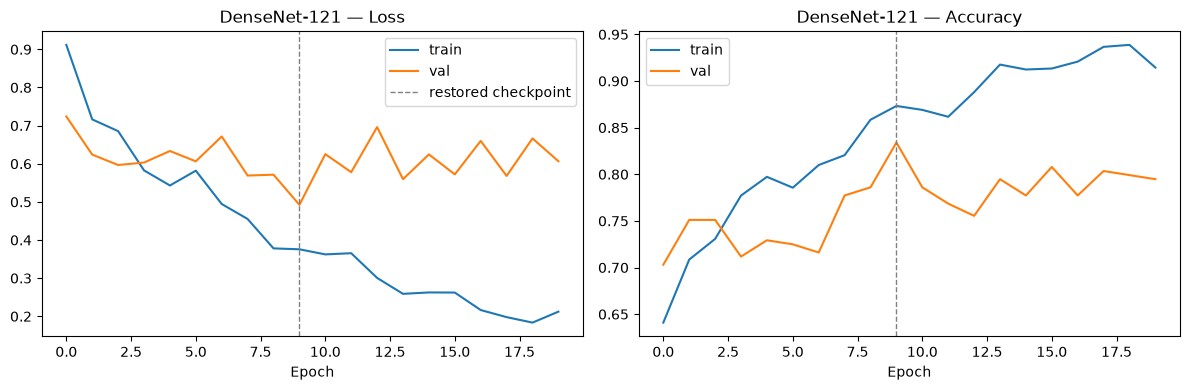

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "DenseNet-121", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "DenseNet-121")

## Evaluate on the test set

[DenseNet-121] Test accuracy: 0.813


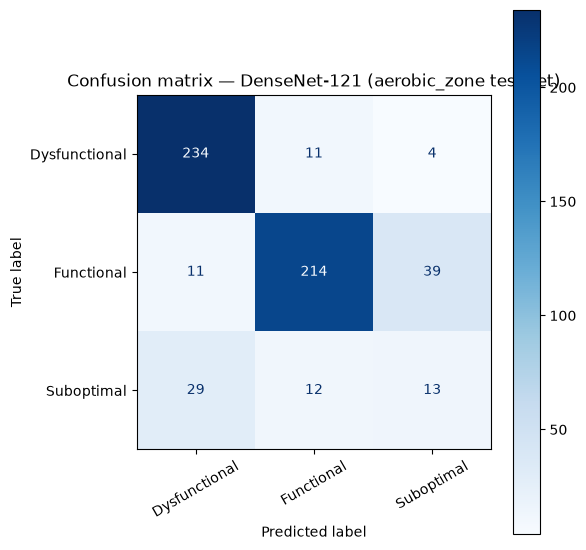

               precision    recall  f1-score   support

Dysfunctional      0.854     0.940     0.895       249
   Functional      0.903     0.811     0.854       264
   Suboptimal      0.232     0.241     0.236        54

     accuracy                          0.813       567
    macro avg      0.663     0.664     0.662       567
 weighted avg      0.818     0.813     0.813       567



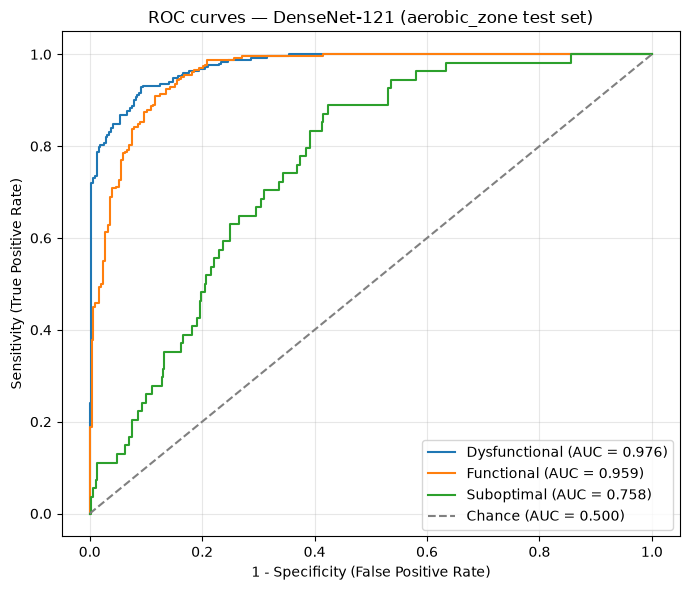

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.976
  Functional     : 0.959
  Suboptimal     : 0.758

Mean AUC (over 3/3 classes with test examples): 0.898


(np.float64(0.8130511463844797),
 {'Dysfunctional': 0.9756636609330402,
  'Functional': 0.9594459445944595,
  'Suboptimal': 0.7576348278102664})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "DenseNet-121", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("DenseNet-121", "densenet121")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_densenet121_chronological.pkl


Saved model weights to ../models/pad/aerobic_zone_densenet121_cnn.pt
